First, we install necessary libraries.

In [1]:
%pip install -r lib/requirements.txt

Note: you may need to restart the kernel to use updated packages.


In [2]:
# Code imports
from lib.opt_types import *
from lib.utils import *

# First Order Methods - 30 points

Following the regularized formulation in [Part 1, equation (2)](Part%201%20-%20Theory.ipynb#eq-regularized-estimator), we now consider binary logistic regression. Here $f$ is the average negative log-likelihood over the $n$ samples, as implemented by the helper function. We solve:

<a id="eq-binary-objective"></a>

$$
	\mathbf{x}^\star=\arg\min_{\mathbf{x} \in \mathbb{R}^p} f_\mu(\mathbf{x}), \qquad f_\mu(\mathbf{x}) := f(\mathbf{x}) + \frac{\mu}{2}\|\mathbf{x}\|_2^2.
\tag{3}
$$

The optimality condition of [(3)](#eq-binary-objective) is

<a id="eq-optimality"></a>

$$
\nabla f_\mu({\mathbf x}^\star) = \frac{1}{n}\sum_{i=1}^n -b_i \sigma(-b_i \cdot \mathbf{a}_i^T\mathbf{x}^\star)\mathbf{a}_i + \mu \mathbf{x}^\star = 0. \tag{4}
$$

Thanks to convexity, condition [(4)](#eq-optimality) is in fact the necessary and sufficient condition for $\mathbf x^\star$ to be optimal.
We can equivalently write this condition as

<a id="eq-fixed-point"></a>

$$
\mathbf x^\star = {\mathbf x}^\star - \mathbf{B} \nabla f_\mu({\mathbf x}^\star) \tag{5}
$$

for any symmetric, positive definite matrix $\mathbf{B}$. 
This is a fixed-point formulation of [(3)](#eq-binary-objective), which will be used to develop first-order methods.


Notice that choosing $\mathbf{B} = \alpha \mathbb{I}$ with $\alpha > 0$ in the formulation [(5)](#eq-fixed-point) suggests that the gradient descent method can be used to solve [(3)](#eq-binary-objective). 

In this part, you will implement different variants of the gradient descent algorithm. 


### Code structure:

A `Function` is a type that has the following attributes:

```python
@dataclass
class Function:
    f              # The function that is being minimized
    grad           # The gradient of the function
    minimum        # The minimum value of the function
    strng_cvx      # The strong convexity constant, if it admits one
    lips_grad      # The smoothness constant, if it admits one
```

For a provided `Function` object `f`:
- You can evaluate the function at a point `x` by simply writing `f(x)`.
- You can evaluate the gradient at a point `x` by writing `f.grad(x)`.
- You can get the smoothness constant by writing `f.lips_grad`.
- You can get the strong convexity constant by writing `f.strng_cvx`



The helper provides the objective $f_\mu$ as the object `f` and an initial point `x_zero`.

In [3]:
from lib.part_one import f, x_zero

The provided `test` function runs a method on the strongly convex quadratic $x \mapsto \frac{1}{2}x^\top M x$, starting from $x_0 = \begin{bmatrix} 100.0& 100.0 \end{bmatrix}$. By default, it runs 100 iterations. For example, after implementing `GD`, run

```python
test(GD)
```

<div class="alert alert-block alert-success">
<b>Run the cells in order.</b> Later cells use variables defined in earlier cells.
</div>

### Variants of Gradient Descent

Now you will implement various methods to iteratively improve the initial guess `x_zero`.

__(a)__ (2 points) The main ingredients of the gradient descent algorithm are the descent direction (the negative gradient) and the step-size $\alpha_k$. 
In this part, we consider the gradient descent algorithm with constant step-size ${1}/{L}$, i.e., $\alpha_k = {1}/{L}$ for any $k = 0,1,...$ where $L$ is the gradient-Lipschitz constant of the function `f`. 

Gradient Descent, as an iterative scheme, only tracks the current iterate `x_k` and the step size `alpha_k`. We store them both in a state variable that holds both these attributes:

In [4]:
@dataclass
class GD_state(OptState):
    x_k: Vector
    alpha_k: float

Given a function `f` and a state at some iteration $k$, recall how GD updates the state and fill in the following cell:

In [5]:
def GD_update(f, state):
    x_k, alpha_k = state
    x_next = x_k - alpha_k * f.grad(x_k)  # FILL
    return GD_state(x_k=x_next, alpha_k=alpha_k)

Having defined the `GD_update` which updates a given state, we now need to initialize the state. Fill in the cell below, recalling that you are given an initial guess `x_zero`, and the fact that we are using a fixed step size corresponding to the smoothness constant of `f`.

In [6]:
def GD_initialize(f, x_zero):
    x_k = x_zero  # FILL
    alpha_k = 1.0 / f.lips_grad  # FILL
    return GD_state(x_k, alpha_k)

With the initialization and the update scheme specified, we define the algorithm in the cell below:

In [7]:
GD = OptAlgorithm(name="GD", init_state = GD_initialize, state_update = GD_update)

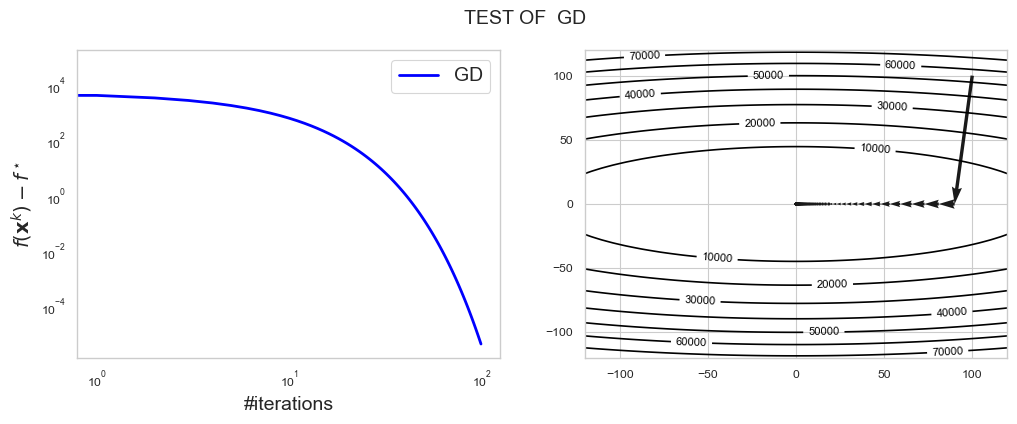

In [8]:
test(GD)

We now notice that the objective function is strongly convex. Therefore, we can select the constant step-size $\alpha$ as $2/(L+\mu)$ to get a faster convergence rate. We call this algorithm `GDstr`.

Both `GD` and `GDstr` have the same state update but only differ in the stepsize they use. Implement this variant of the gradient descent method by completing the code:

In [9]:
def GDstr_initialize(f, x_zero):
    x_k = x_zero  # FILL
    alpha_k = 2.0 / (f.lips_grad + f.strng_cvx)  # FILL
    return GD_state(x_k, alpha_k)

GDstr = OptAlgorithm(name="GDstr", init_state=GDstr_initialize, state_update=GD_update)

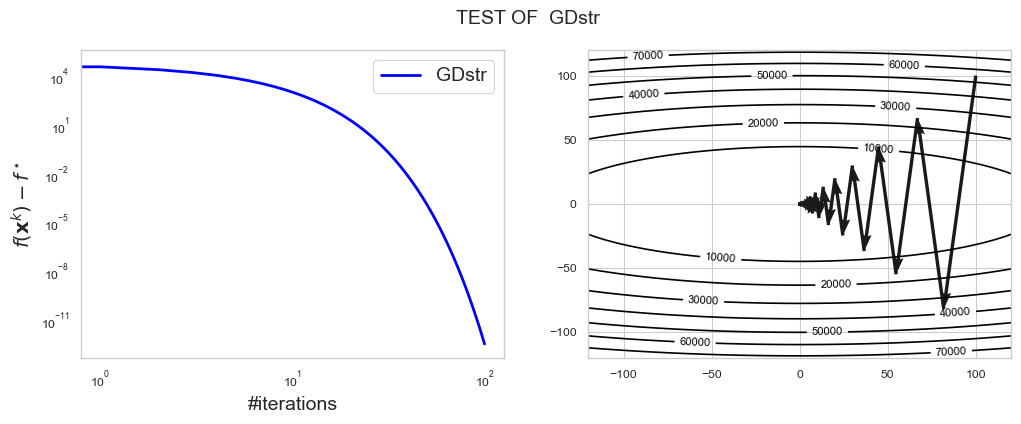

In [10]:
test(GDstr)

__(b-1)__ (1.5 points) We can accelerate the above gradient descent algorithm with the following scheme ($t_0=1$):

$$
\begin{array}{ll}
\mathbf{x}^{k+1} &:=  \mathbf{y}^k - \alpha_k\nabla{f_\mu}(\mathbf{y}^k),\\
t_{k+1} &:= \frac{1}{2}(1 + \sqrt{1 + 4t_k^2})\\
\mathbf{y}^{k+1} &:= \mathbf{x}^{k+1} + \frac{t_k-1}{t_{k+1}}\big(\mathbf{x}^{k+1} - \mathbf{x}^k\big).
\end{array}
$$

Implement this algorithm with constant step-size $\alpha = 1/L$, by completing the missing parts of the following cells.

First we define the state that the algorithm updates at each iteration:

In [11]:
@dataclass
class AGD_state(OptState):
    x_k: Vector
    y_k: Vector
    t_k: float
    alpha_k: float

Given this `state` and a function `f` to optimize, write the update step of accelerated gradient descent:

In [12]:
def AGD_update(f, state):
    x_k, y_k, t_k, alpha_k = state
    next_x_k = y_k - alpha_k * f.grad(y_k)  # FILL
    next_t_k = 0.5 * (1.0 + np.sqrt(1.0 + 4.0 * t_k**2))  # FILL
    next_y_k = next_x_k + (t_k - 1.0) / next_t_k * (next_x_k - x_k)  # FILL
    next_alpha_k = alpha_k  # FILL
    return AGD_state(next_x_k, next_y_k, next_t_k, next_alpha_k)

Define the initial state of AGD in the cell below:

In [13]:
def AGD_initialize(f, x_zero):
    # x^0 = y^0 = x_zero, t_0 = 1, alpha = 1/L
    return AGD_state(x_k=x_zero, y_k=x_zero, t_k=1.0, alpha_k=1.0 / f.lips_grad)

We have all the necessary ingredients to define the optimization algorithm in the following cell:

In [14]:
AGD = OptAlgorithm(name="AGD", init_state=AGD_initialize, state_update=AGD_update)

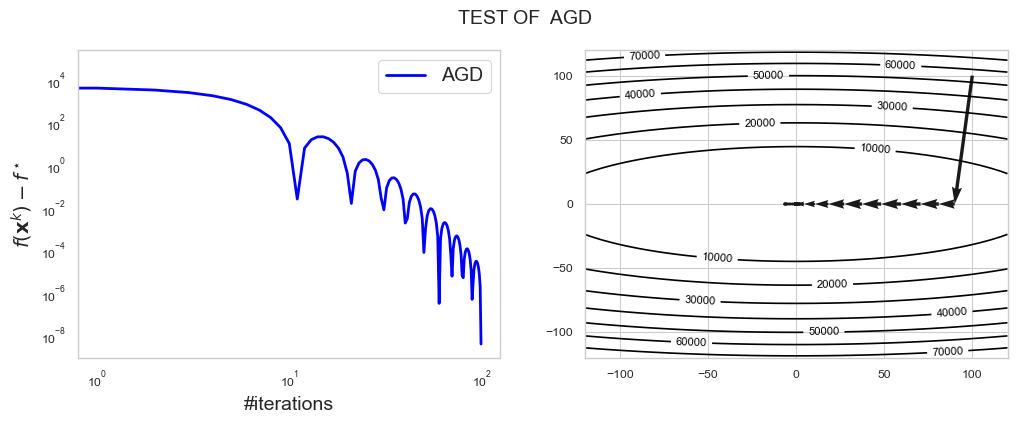

In [15]:
test(AGD)

__(b-2)__ (1 point)

Note that the objective function is strongly convex. Therefore, we can use the accelerated gradient algorithm for strongly convex objectives to converge faster. This variant can be summarized as follows:

$$
\left\{
\begin{aligned}
\mathbf{x}^{k+1} &:= \mathbf{y}^k - \alpha_k \nabla f_\mu(\mathbf{y}^k),\\
\mathbf{y}^{k+1} &:= \mathbf{x}^{k+1} + m\big(\mathbf{x}^{k+1} - \mathbf{x}^k\big).
\end{aligned}
\right.
$$
 
Implement this variant of the accelerated gradient method by completing the following cells. Try different values of $m$ and comment on what should be the best value for this constant. Do the practical results follow the theory?

In [16]:
@dataclass
class AGDstr_state(OptState):
    x_k: Vector
    y_k: Vector
    alpha_k: float
    m_strongcvx: float

In [17]:
def AGDstr_update(f, state):
    x_k, y_k, alpha_k, m_strongcvx = state
    next_x_k = y_k - alpha_k * f.grad(y_k)  # FILL
    next_y_k = next_x_k + m_strongcvx * (next_x_k - x_k)  # FILL
    return AGDstr_state(next_x_k, next_y_k, alpha_k, m_strongcvx)


def AGDstr_initialize(f, x_zero, m_strongcvx=None):
    # Theoretical momentum (Lecture 5, AGD-muL): m = (sqrt(L) - sqrt(mu)) / (sqrt(L) + sqrt(mu))
    if m_strongcvx is None:
        sL, sm = np.sqrt(f.lips_grad), np.sqrt(f.strng_cvx)
        m_strongcvx = (sL - sm) / (sL + sm)  # FILL
    return AGDstr_state(x_k=x_zero, y_k=x_zero, alpha_k=1.0 / f.lips_grad, m_strongcvx=m_strongcvx)

In [18]:
AGDstr = OptAlgorithm(name="AGDstr", init_state=AGDstr_initialize, state_update=AGDstr_update)

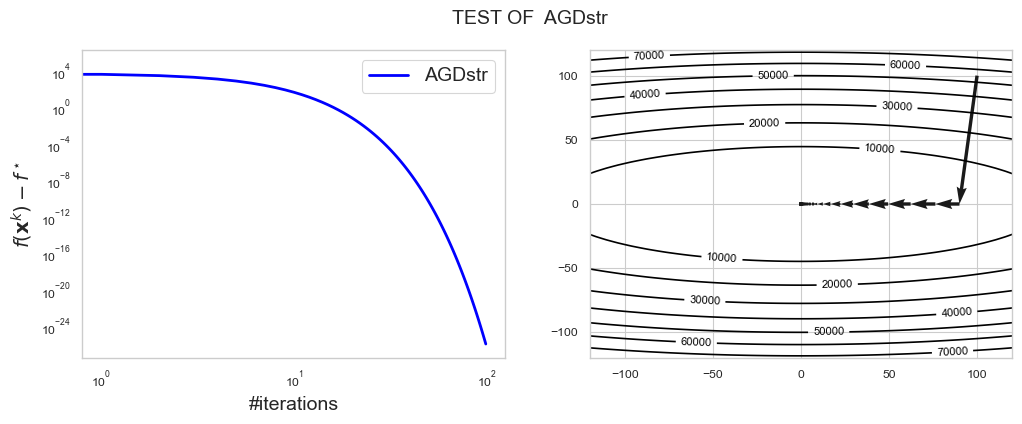

In [19]:
test(AGDstr)

theoretical m on the quadratic: 0.5194938532959157
L_quadratic: 10.0 , mu_quadratic: 1.0
theoretical m on the logistic problem: 0.999698770722138
L_logistic: 44069.16257870429 , mu_logistic: 0.001


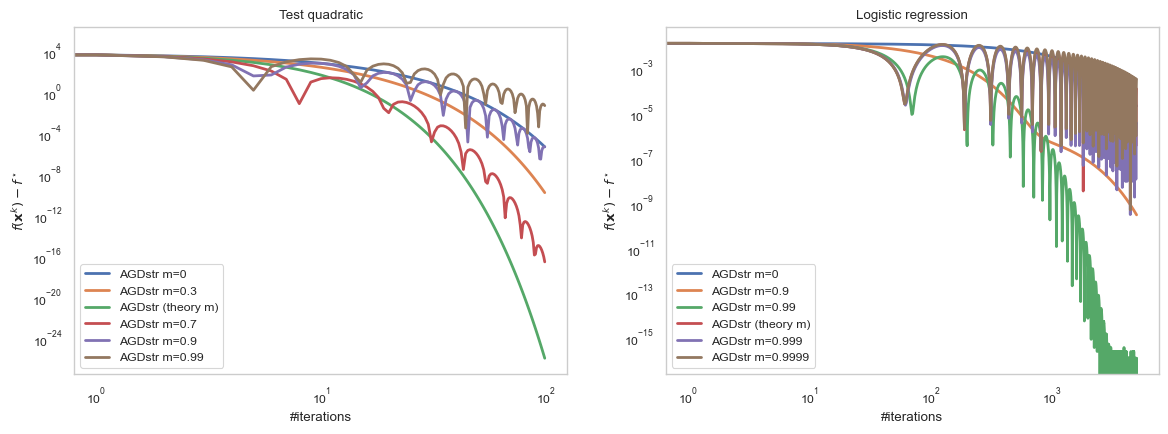

In [20]:
# Comparison of different momentum values m, on the test quadratic (L=10, mu=1, the largest and smallest eigenvalues of the Hessian M respecively)
#  and on the logistic problem.
M_quad = np.array([[1.0, 0.0], [0.0, 10.0]])
quadratic = Function(f=lambda u: 0.5*np.dot(u, np.dot(M_quad, u)), grad=lambda u: np.dot(M_quad, u),
                     minimum=0.0, lips_grad=10.0, strng_cvx=1.0)

def make_AGDstr(m):
    name = "AGDstr (theory m)" if m is None else f"AGDstr m={m:g}"
    return OptAlgorithm(name=name, init_state=lambda f, x0, m=m: AGDstr_initialize(f, x0, m), state_update=AGDstr_update)

sL, sm = np.sqrt(quadratic.lips_grad), np.sqrt(quadratic.strng_cvx)
print("theoretical m on the quadratic:", (sL - sm) / (sL + sm))
print("L_quadratic:",quadratic.lips_grad, ", mu_quadratic:", quadratic.strng_cvx)

sL, sm = np.sqrt(f.lips_grad), np.sqrt(f.strng_cvx)
print("theoretical m on the logistic problem:", (sL - sm) / (sL + sm))
print("L_logistic:",f.lips_grad, ", mu_logistic:", f.strng_cvx)

fig, axs = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, fun, x0, K, ms in [(axs[0], quadratic, np.array([100.0, 100.0]), 100, [0.0, 0.3, None, 0.7, 0.9, 0.99]),
                           (axs[1], f, x_zero, 5000, [0.0, 0.9, 0.99, None, 0.999, 0.9999])]:
    for m in ms:
        tr = run(make_AGDstr(m), fun, x0, K)
        ax.plot(np.array(tr.values) - fun.minimum, lw=2, label=make_AGDstr(m).name)
    ax.set_xscale("log"); ax.set_yscale("log"); ax.grid(); ax.legend()
    ax.set_xlabel("#iterations"); ax.set_ylabel(r"$f(\mathbf{x}^k) - f^\star$")
axs[0].set_title("Test quadratic"); axs[1].set_title("Logistic regression")
plt.show()

**Testing different values of $m$**

The theoretical best momentum (Lecture 5, AGD-$\mu L$, with $\alpha=1/L$) is
$$
m_{\text{theory}}=\frac{\sqrt{L}-\sqrt{\mu}}{\sqrt{L}+\sqrt{\mu}}=\frac{\sqrt\kappa-1}{\sqrt\kappa+1},\qquad \kappa=\frac{L}{\mu}.
$$
The momentum controls how much of the previous step we reuse. If $m<m_{\text{theory}}$, momentum is underused and the method is slower (for $m=0$ we recover GD). If $m>m_{\text{theory}}$, the method overshoots and oscillates.

We tested $m\in\{0,\,0.3,\,m_{\text{theory}},\,0.7,\,0.9,\,0.99\}$ on the test quadratic ($L=10$, $\mu=1$, so $m_{\text{theory}}\approx0.52$), and $m\in\{0,\,0.9,\,0.99,\,m_{\text{theory}},\,0.999,\,0.9999\}$ on the logistic problem ($m_{\text{theory}}\approx0.9997$).

- **Quadratic:** the theoretical value is the best. It reaches a gap of about $10^{-26}$ after 100 iterations, against $10^{-17}$ for $m=0.7$, $10^{-10}$ for $m=0.3$ and $4\cdot10^{-6}$ for $m=0$. The values $m\ge0.9$ are too large and oscillate. The practical results follow the theory exactly, because $L$ and $\mu$ are known exactly.
- **Logistic regression:** the best value is $m\approx0.99$, not the theoretical $0.9997$. With $m=0.99$ the gap goes below $10^{-10}$ after about 1100 iterations. The values $m\ge0.999$ oscillate, and $m=0.9$ is stable but slow.


**Do the practical results follow the theory?** Qualitatively yes: there is a best $m$, smaller values are slower and larger values oscillate. Quantitatively, on the logistic problem, no. The formula uses $L\approx4.4\cdot10^4$ and $\mu=10^{-3}$, so $\kappa\approx4.4\cdot10^7$ and $m_{\text{theory}}\approx0.9997$. But these are **worst-case** constants, valid at every point $\mathbf x$ rather than the ones the iterates actually see. In fact, this is how these constants were calculated in lib:

Differentiating (4) once more (with $b_i^2=1$) gives the Hessian, which describes the curvature of $f_\mu$:
$$
\nabla^2 f_\mu(\mathbf x)=\underbrace{\frac1n\sum_{i=1}^n\sigma_i(1-\sigma_i)\,\mathbf a_i\mathbf a_i^T}_{\text{data part}}+\mu I,\qquad \sigma_i=\sigma(-b_i\mathbf a_i^T\mathbf x),\quad \sigma_i(1-\sigma_i)\in(0,\tfrac14].
$$

- **$\mu$ = guaranteed minimum curvature.** The data part is never negative, so the curvature in any direction is at least $\mu$. This is why $\mu=10^{-3}$ (the ridge parameter) is a valid bound. It is pessimistic because it assumes the data part gives *no* curvature in the worst direction. On our shots it does give some, so the true minimum curvature is larger than $\mu$.
- **$L$ = guaranteed maximum curvature.** Using $\sigma_i(1-\sigma_i)\le1$ and bounding the largest eigenvalue of $A^TA$ by the sum of all its eigenvalues, $\|A\|_F^2$, we get $\nabla^2 f_\mu\preceq\big(\frac1n\|A\|_F^2+\mu\big)I=LI$. It is pessimistic because both steps overestimate: $\sigma_i(1-\sigma_i)$ is at most $\frac14$ and is small for confidently classified shots, and the sum of eigenvalues is at least the largest one.

So $L$ is too big and $\mu$ is too small, which makes $\kappa=L/\mu$ much larger than the condition number the iterates really see. Then $m_{\text{theory}}$ is too close to $1$, and the method oscillates. The best empirical value, $m\approx0.99$, is smaller. 

The best $m$ is only as good as our knowledge of the effective $L$ and $\mu$.

__(c)__ (5 points) We can obtain better performance by considering a line search procedure, which adapts the step-size $\alpha_k$ to the local geometry. 
The line-search strategy to determine the step-size $\alpha_k$ for the standard GD algorithm,
$\mathbf{x}^{k+1}=\mathbf{x}^k-\alpha_k\nabla f_\mu(\mathbf{x}^k),$
is the following: 

Initialize $L_{-1}=L$. At iteration $k\geq0$, use the current iterate $\mathbf{x}^k$ and descent direction $\mathbf{d}^k=-\nabla f_\mu(\mathbf{x}^k)$:

* At each iteration, set $L_{k,0} = \frac{1}{2}L_{k-1}$, where $k$ is the iteration counter. 
* Starting at $i=0$ and increasing $i$ as needed, find the minimum integer $i \geq 0$ that satisfies $f_\mu\left(\mathbf{x}^k + \frac{1}{2^i L_{k,0}} \mathbf{d}^k\right) \leq f_\mu(\mathbf{x}^k) -\frac{1}{2^{i+1} L_{k,0}} \|\mathbf{d}^k\|^2$.
* Set $L_k = {2^i L_{k,0}}$ and use the step-size $\alpha_k := \frac{1}{L_k}$ to take the accepted gradient step.

Complete the missing parts in order to implement gradient descent with line-search.

In [25]:
@dataclass
class LS_GD_state(OptState):
    x_k: Vector
    L_k: float  # last accepted smoothness estimate L_{k-1}

In [26]:
def LS_GD_update(f, state):
    x_k, prev_L = state
    L_k_0 = prev_L / 2
    d_k = -f.grad(x_k)
    f_x, sq_norm = f(x_k), np.dot(d_k, d_k)
    i = 0
    while True:
        L_k_trial = 2**i * L_k_0
        alpha_k = 1.0 / L_k_trial
        next_x_k = x_k + alpha_k * d_k
        if f(next_x_k) <= f_x - 0.5 * alpha_k * sq_norm:
            break
        i += 1
    return LS_GD_state(x_k=next_x_k, L_k=L_k_trial)

In [27]:
LS_GD = OptAlgorithm(name="LS_GD", init_state = LS_GD_initialize, state_update=LS_GD_update )

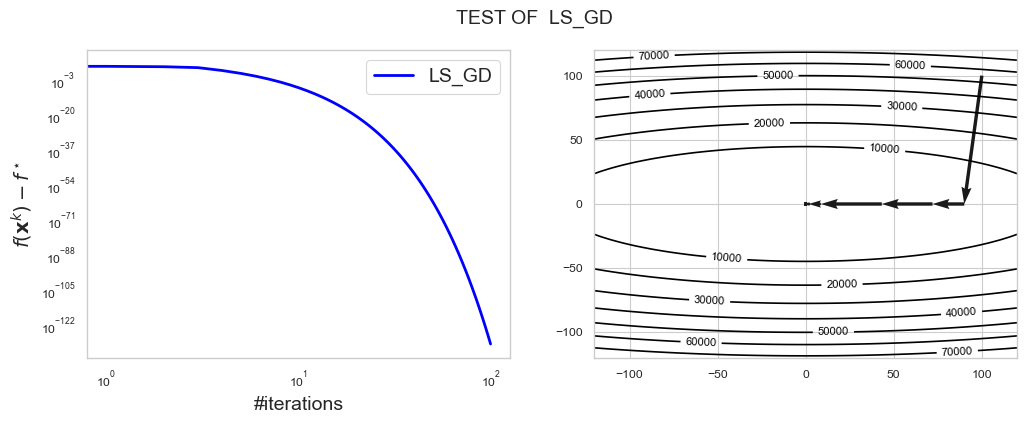

In [28]:
test(LS_GD)

We now incorporate a line-search enhancement to the accelerated gradient method implemented in (b-1). At iteration $k$, 
we have the current iterate $\mathbf{x}^k$ together with an _intermediate variable_ $\mathbf{y}^k$ and its corresponding direction $\mathbf{d}^k=-\nabla f_\mu(\mathbf{y}^k)$. **Note that the intermediate variable is then used in the gradient step and hence the line-search will be performed on it to determine the step-size**.


Perform a line-search strategy with respect to $\mathbf{y}^k$ and direction $\mathbf{d}^k$ to determine the step-size $\alpha_k$ as follows:

Initialize $L_{-1}=L$. Then, for $k\geq0$:

* At each iteration, set $L_{k,0} = \frac{1}{2}L_{k-1}$, where $k$ is the iteration counter. 
* Starting at $i=0$ and increasing $i$ as needed, find the minimum integer $i \geq 0$ that satisfies $f_\mu\left(\mathbf{y}^k + \frac{1}{2^i L_{k,0}} \mathbf{d}^k\right) \leq f_\mu(\mathbf{y}^k) -\frac{1}{2^{i+1} L_{k,0}} \|\mathbf{d}^k\|^2$.
* Set $L_k = {2^i L_{k,0}}$ and use the step-size $\alpha_k := \frac{1}{L_k}$.
 
Update the next iterations:
$$
\left\{
\begin{aligned}
\mathbf{x}^{k+1} &:= \mathbf{y}^k - \alpha_k \nabla f_\mu(\mathbf{y}^k),\\
t_{k+1} &:= \frac{1}{2}\left(1 + \sqrt{1 + 4\frac{L_k}{L_{k-1}}t_k^2}\right),\\
\mathbf{y}^{k+1} &:= \mathbf{x}^{k+1} + \frac{t_k-1}{t_{k+1}}\big(\mathbf{x}^{k+1} - \mathbf{x}^k\big).
\end{aligned}
\right.
$$

Complete the missing parts in order to implement accelerated gradient descent with line-search.

In [29]:
@dataclass
class LS_AGD_state(OptState):
    x_k: Vector
    y_k: Vector
    t_k: float
    L_k: float 

In [30]:
def LS_AGD_update(f, state):
    x_k, y_k, t_k, prev_L = state
    d_k = -f.grad(y_k)
    f_y, sq_norm = f(y_k), np.dot(d_k, d_k)
    L_k_0 = prev_L / 2
    i = 0
    while True:
        L_trial = 2**i * L_k_0
        alpha_k = 1.0 / L_trial
        next_x_k = y_k + alpha_k * d_k
        if f(next_x_k) <= f_y - 0.5 * alpha_k * sq_norm:
            break
        i += 1
    next_t_k = 0.5 * (1 + np.sqrt(1 + 4 * (L_trial / prev_L) * t_k**2))
    next_y_k = next_x_k + ((t_k - 1) / next_t_k) * (next_x_k - x_k)
    return LS_AGD_state(x_k=next_x_k, y_k=next_y_k, t_k=next_t_k, L_k=L_trial)

def LS_AGD_initialize(f, x_zero):
    return LS_AGD_state(x_k=x_zero, y_k=x_zero, t_k=1.0, L_k=f.lips_grad)  # x^0=y^0, t_0=1, L_{-1}=L

In [31]:
LS_AGD = OptAlgorithm(name="LS_AGD", init_state=LS_AGD_initialize, state_update=LS_AGD_update )

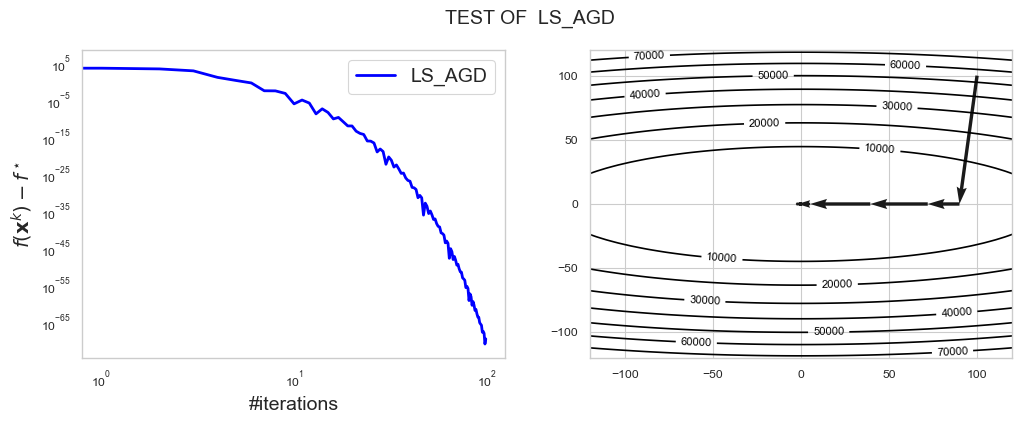

In [32]:
test(LS_AGD)

__(d)__ (3 points) The accelerated gradient method need not decrease the objective at every iteration: we may have $f_\mu(\mathbf{x}^{k+1})>f_\mu(\mathbf{x}^k)$ at some iterations.
To prevent such behavior, we can use the so-called adaptive restart strategy. 
In short, this strategy can be explained as follows: 
At each iteration, whenever $\mathbf{x}^{k+1}$ is computed, we evaluate $f_\mu(\mathbf{x}^{k+1})$ and compare it with $f_\mu(\mathbf{x}^k)$: 

* If $f_\mu(\mathbf{x}^k) < f_\mu(\mathbf{x}^{k+1})$, restart the iteration, i.e., recompute $\mathbf{x}^{k+1}$ by setting $\mathbf{y}^{k} := \mathbf{x}^{k}$ and $t_{k} := 1$;
* Otherwise, let the algorithm continue.


This strategy requires the evaluation of the function value at each iteration, which increases the computational complexity of the overall algorithm. 

Implement the adaptive restart strategy which uses the function values for the accelerated gradient algorithm with constant step-size $\alpha_k=1/L$ 
by completing the function:

In [33]:
@dataclass
class AGDR_state(AGD_state):
    x_k: Vector
    y_k: Vector
    t_k: float
    alpha_k: float 


In [34]:
def AGDR_update(f, state):
    x_k, y_k, t_k, alpha_k= state
    
    next_x_k = y_k - alpha_k * f.grad(y_k)
    if f(next_x_k) > f(x_k):
        y_k = x_k
        t_k = 1.0
        next_x_k = y_k - alpha_k * f.grad(y_k)
    
    next_t_k = (1 + (1 + 4 * t_k**2)**0.5) / 2
    next_y_k = next_x_k + (t_k - 1) / next_t_k * (next_x_k - x_k) 
    
    return AGDR_state(x_k = next_x_k, y_k = next_y_k, t_k=next_t_k, alpha_k =alpha_k)

AGDR_initialize = AGD_initialize

In [35]:
AGDR = OptAlgorithm(name="AGDR", init_state = AGDR_initialize, state_update=AGDR_update)

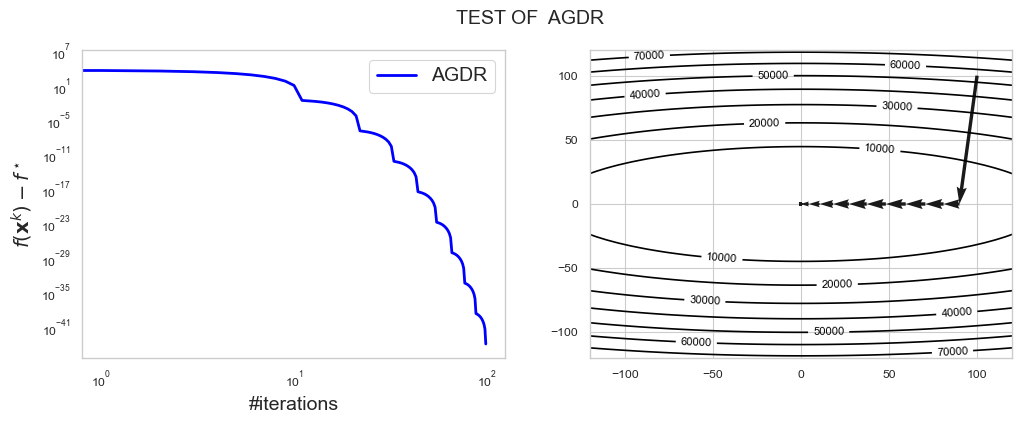

In [36]:
test(AGDR)

__(e)__ (Self-study, 0 points)
Combine line search, acceleration, and objective-based restart by completing `LS_AGDR_update`.

**Hint:** If the proposed step increases the objective, reset $\mathbf{y}^k=\mathbf{x}^k$ and $t_k=1$. Repeat the line search from this reset point and recompute the gradient step before updating the momentum.


In [37]:
@dataclass 
class LS_AGDR_state(LS_AGD_state):
    pass

In [38]:
def LS_AGDR_update(f, state):
    x_k, y_k, t_k, prev_L = state

    # Line search from y^k
    d_k = -f.grad(y_k)
    f_y, sq_norm = f(y_k), np.dot(d_k, d_k)
    L_k_0 = prev_L / 2
    i = 0
    while True:
        L_trial = 2**i * L_k_0
        alpha_k = 1.0 / L_trial
        next_x_k = y_k + alpha_k * d_k
        if f(next_x_k) <= f_y - 0.5 * alpha_k * sq_norm:
            break
        i += 1
    L_k = L_trial

    # Restart: if the objective increased, reset y^k = x^k, t_k = 1 and redo the line search from x^k
    if f(next_x_k) > f(x_k):
        y_k, t_k = x_k, 1.0
        d_k = -f.grad(y_k)
        f_y, sq_norm = f(y_k), np.dot(d_k, d_k)
        i = 0
        while True:
            L_trial = 2**i * L_k_0
            alpha_k = 1.0 / L_trial
            next_x_k = y_k + alpha_k * d_k
            if f(next_x_k) <= f_y - 0.5 * alpha_k * sq_norm:
                break
            i += 1
        L_k = L_trial

    next_t_k = 0.5 * (1 + np.sqrt(1 + 4 * (L_k / prev_L) * t_k**2))
    next_y_k = next_x_k + ((t_k - 1) / next_t_k) * (next_x_k - x_k)
    return LS_AGDR_state(x_k=next_x_k, y_k=next_y_k, t_k=next_t_k, L_k=L_k)

LS_AGDR_initialize = LS_AGD_initialize

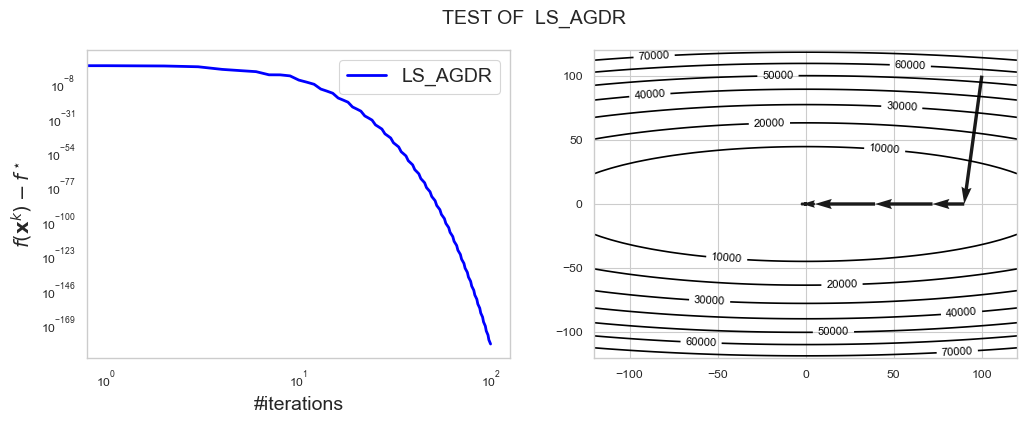

In [39]:
LS_AGDR = OptAlgorithm(name="LS_AGDR", init_state=LS_AGDR_initialize, state_update=LS_AGDR_update)

test(LS_AGDR)

__(f)__ (4 points) We can also apply an optimization technique that does not exploit the knowledge of the Lipschitz constant, and instead adapts to the local geometry by making use of past gradient information. This scalar AdaGrad variant divides the step size by the square root of the accumulated squared gradient norms. Starting with $Q_0 = 0$ it iterates as follows:

$$
\left\{\begin{array}{ll}
Q_{k+1} &{\!\!\!\!}= Q_k + \|\nabla f_\mu(\mathbf{x}^k)\|^2 \\
\mathbf{H}_k &{\!\!\!\!}= (\sqrt{Q_{k+1}} + \delta) I \\
\mathbf{x}^{k+1} &{\!\!\!\!}= \mathbf{x}^k - \alpha \mathbf{H}_k^{-1} \nabla f_\mu(\mathbf{x}^k)
\end{array}\right.
$$

Complete the missing parts in the function AdaGrad in order to implement the above adaptive gradient method using $\alpha = 1$, $\delta = 10^{-5}$.

In [41]:
@dataclass
class AdaGrad_state(OptState):
    x_k: Vector
    Q_k: float
    alpha_k: float
    delta_k: float

In [42]:
def AdaGrad_update(f, state):
    x_k, Q_k, alpha_k, delta_k = state
    g = f.grad(x_k)
    next_Q_k = Q_k + np.linalg.norm(g)**2
    H_k = (np.sqrt(next_Q_k) + delta_k) * np.eye(len(x_k))
    next_x_k = x_k - alpha_k * np.linalg.inv(H_k).dot(g)
    
    return AdaGrad_state(next_x_k, next_Q_k, alpha_k, delta_k)

def AdaGrad_initialize(f, x_zero):
    return AdaGrad_state(x_zero, 0.0, 1.0, 1e-5)

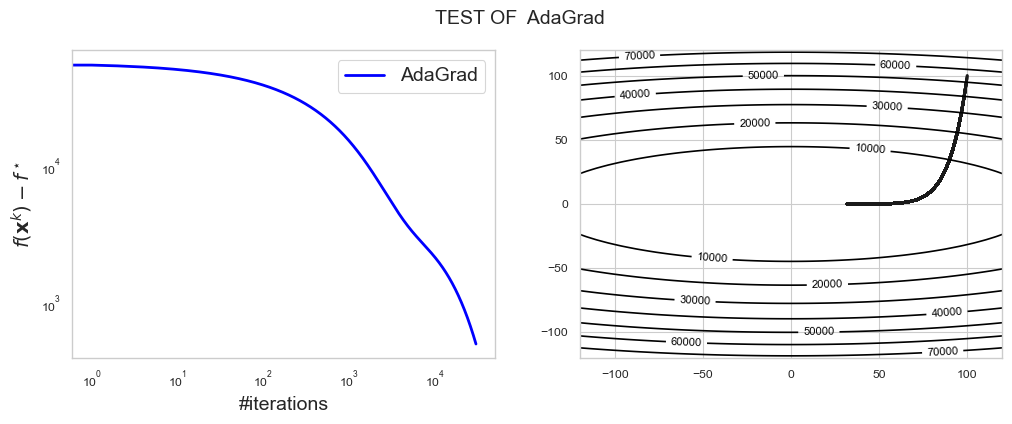

In [43]:
AdaGrad = OptAlgorithm(name="AdaGrad", init_state=AdaGrad_initialize, state_update=AdaGrad_update)
test(AdaGrad, maxiter=30000)

__(g)__ (2.5 points) Another famous adaptive optimization method is called the ADAptive Moment estimation algorithm, also known as ADAM, 

$$
\left\{\begin{array}{ll}
\mathbf{g}_k &{\!\!\!\!} = \nabla f_\mu(\mathbf{x}^{k}) \\
\mathbf{m}_{k+1} &{\!\!\!\!} = \beta_1 \mathbf{m}_{k} + (1-\beta_1)\mathbf{g}_k \ \textrm{$\leftarrow$ Momentum}\\
\mathbf{v}_{k+1} &{\!\!\!\!} = \beta_2 \mathbf{v}_{k} + (1-\beta_2)\mathbf{g}_k^2 \ \textrm{$\leftarrow$ Adaptive term}\\
\hat{\mathbf{m}}_{k+1} &{\!\!\!\!} = \mathbf{m}_{k+1} / (1-\beta_1^{k+1})\\
\hat{\mathbf{v}}_{k+1} &{\!\!\!\!} = \mathbf{v}_{k+1} / (1-\beta_2^{k+1}) \ \textrm{$\leftarrow$ Scaling for removing bias}\\
\mathbf{H}_{k+1} &{\!\!\!\!} \ = \sqrt{\hat{\mathbf{v}}_{k+1}} + \epsilon \\
\mathbf{x}^{k+1} &{\!\!\!\!} = \mathbf{x}^k - \alpha \hat{\mathbf{m}}_{k+1} / \mathbf{H}_{k+1}
\end{array}\right.
$$

Note that all operations shown above, when applied to vectors, are applied element-wise. In particular, $\mathbf{g}_k^2$ is a vector of the same size as $\mathbf{g}_k$ where each element is squared.

Complete the missing parts in the cells below in order to implement the above adaptive gradient method using $\alpha = 0.1$, $\beta_1 = 0.9$, $\beta_2 = 0.999$ and $\epsilon = 10^{-8}$.

It has been shown that ADAM can fail to converge to the global minimum of a convex problem. The authors provided a variant of ADAM, called AMSgrad in order to fix this convergence issue. However, in practice it is not clear which method performs best. (You are not required to implement this method, but advised to have a look at it for personal interest).

In [44]:
@dataclass
class ADAM_state(OptState):
    x_k: Vector
    m_k: Vector
    v_k: Vector
    beta1: float
    beta2: float
    alpha_k: float
    epsilon: float
    k: int

In [47]:
def ADAM_update(f, state):
    x_k, m_k, v_k, beta1, beta2, alpha_k, epsilon, k = state
    g_k = f.grad(x_k)
    next_m_k = beta1 * m_k + (1 - beta1) * g_k
    next_v_k = beta2 * v_k + (1 - beta2) * (g_k * g_k)
    next_m_hat = next_m_k / (1 - beta1**(k+1))
    next_v_hat = next_v_k / (1 - beta2**(k+1))
    next_H_k = np.sqrt(next_v_hat) + epsilon
    next_x_k = x_k - alpha_k * next_m_hat / next_H_k

    
    return ADAM_state(next_x_k, next_m_k, next_v_k, beta1, beta2, alpha_k, epsilon, k+1)

def ADAM_initialize(f, x_zero):
    return ADAM_state(x_zero, np.zeros_like(x_zero), np.zeros_like(x_zero), 0.9, 0.999, 0.1, 1e-8, 0)
    

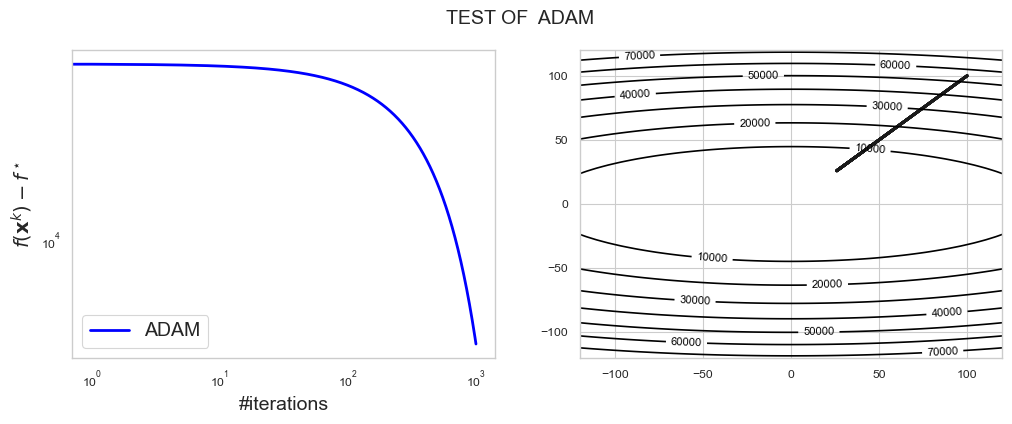

In [48]:
ADAM = OptAlgorithm(name="ADAM", init_state=ADAM_initialize, state_update=ADAM_update)

test(ADAM, maxiter=1000)

## Schedule-Free Optimizer
Schedule-Free learning replaces the momentum of an underlying optimizer with a combination of interpolation and averaging. In the case of gradient descent, the basic Schedule-Free update is:

$$
\begin{align*}
y_{t} & = (1-\beta)z_{t} + \beta x_{t},\\
z_{t+1} & =z_{t}-\gamma\nabla f_\mu(y_{t}),\\
x_{t+1} & =\left(1-\frac{1}{t+1}\right)x_{t}+\frac{1}{t+1}z_{t+1},
\end{align*}
$$

Evaluate the objective at the averaged iterates $x_t$. The iterates $z_t$ receive the gradient updates, while gradients are evaluated at $y_t$. The updates to $z$ correspond to the underlying optimizer, in this case a simple gradient step.

Schedule-Free learning uses a constant learning rate together with averaging. Its performance depends on the problem and chosen parameters. Only $x_t$ and $z_t$ need to be stored between iterations, since $y_t$ can be computed from them.

Initialize $x_0=z_0$ at `x_zero` and start at $t=0$. Use the constant step size $\gamma=1/L$ and $\beta=0.5$. For the test quadratic, $L=10$, so $\gamma=0.1$.

**(a)** (1 point) Complete the initializer and update for the Schedule-Free optimizer.


In [42]:
@dataclass
class Scheduler_free_state(OptState):
    x_k: Vector  # averaged iterate (the one we evaluate)
    z_k: Vector  # base-optimizer iterate (receives the gradient steps)
    t: int

In [43]:
def Scheduler_free_update(f, state, beta=0.5):
    x_k, z_k, t = state
    gamma = 1.0 / f.lips_grad
    y_k = (1 - beta) * z_k + beta * x_k
    z_next = z_k - gamma * f.grad(y_k)
    c = 1.0 / (t + 1)
    x_next = (1 - c) * x_k + c * z_next
    return Scheduler_free_state(x_k=x_next, z_k=z_next, t=t + 1)

def Scheduler_free_initialize(f, x_zero):
    return Scheduler_free_state(x_k=x_zero, z_k=x_zero, t=0)

**(b)** (1 point) Run your experiment and discuss why the algorithm is referred to as a schedule-free optimizer. You may refer to [The Road Less Scheduled](https://arxiv.org/abs/2405.15682).

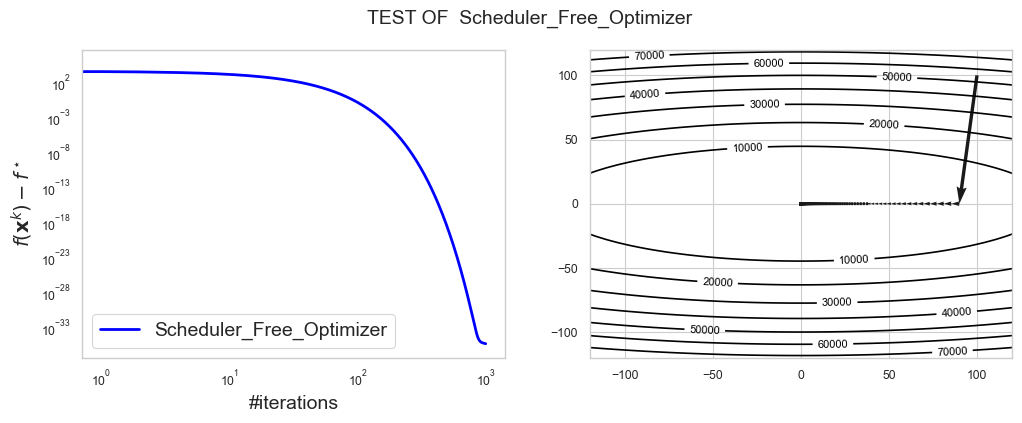

In [44]:
SFO = OptAlgorithm(name="Scheduler_Free_Optimizer", init_state=Scheduler_free_initialize, state_update=Scheduler_free_update)

test(SFO, maxiter=1000)

**(b) Why "schedule-free"?** The plot shows that SFO decreases the objective smoothly and monotonically with one *constant* step size $\gamma=1/L$ and no tuning of any decay schedule.

In standard (S)GD-type methods, convergence to the optimum requires a learning-rate schedule (e.g. $\alpha_k\propto1/\sqrt k$ or a cosine decay to $0$ at a fixed final iteration $T$). The schedule must be chosen in advance, and good performance usually requires knowing the stopping time $T$. Schedule-Free learning replaces this schedule by **averaging**. The base iterate $z_t$ moves with a constant step size and so stays "noisy". The point where we evaluate the objective is the running average $x_{t+1}=\frac{t}{t+1}x_t+\frac1{t+1}z_{t+1}$ (the uniform mean of $z_1,\dots,z_{t+1}$). The averaging damps the noise and plays the role that the step-size decay plays in a scheduled method. The interpolation $y_t=(1-\beta)z_t+\beta x_t$ is where the gradient is evaluated. It provides a momentum-like effect and stabilises the averaged sequence, as in "The Road Less Scheduled". Consequently:

- no decay schedule and no stopping time $T$ are needed (the method is *anytime*);
- only $x_t,z_t$ are stored, so the memory cost is the same as for GD with momentum;
- the only free parameters are $\gamma$ and $\beta$.

*Observation and limitation.* On the quadratic test, SFO converges. On the logistic problem, it converges monotonically, but only at a sublinear $O(1/t)$-like rate ($\approx5\cdot10^{-4}$ after 5000 iterations, i.e. worse than GD). This is the price of uniform averaging: the early iterates, far from $\mathbf x^\star$, keep a weight of order $1/t$ in the average, so the method cannot exploit the strong convexity to get a linear rate. It is therefore best suited to problems where a good schedule is unknown, rather than to deterministic problems where line search or acceleration are available.

## Polyak’s Heavy Ball (PHB) Method

Polyak’s Heavy Ball (PHB) method accelerates gradient descent by adding momentum, modeling a ball rolling over the objective landscape with friction. The continuous-time form is

$$
\ddot{\mathbf{x}} = -a\,\nabla f_\mu(\mathbf{x}) - b\,\dot{\mathbf{x}},
$$

where $a$ controls attraction to the minimum and $b$ provides damping.

The discrete update is

$$
\mathbf{x}_{k+1} = \mathbf{x}_k - \alpha\,\nabla f_\mu(\mathbf{x}_k) + \beta\,(\mathbf{x}_k - \mathbf{x}_{k-1}),
$$

with step size $\alpha$ and momentum $\beta$.

For a strongly convex quadratic with Hessian eigenvalues in $[\mu,L]$, the classical parameter choice is

$$
\alpha = \frac{4}{(\sqrt{L}+\sqrt{\mu})^2}, \qquad 
\beta = \left(\frac{\sqrt{\kappa}-1}{\sqrt{\kappa}+1}\right)^2, \quad \kappa = \frac{L}{\mu},
$$

For these quadratics, the asymptotic convergence factor is

$$
\rho=\frac{\sqrt{\kappa}-1}{\sqrt{\kappa}+1}.
$$

This quadratic result does not guarantee convergence with the same parameters for every smooth, strongly convex objective. On our logistic regression problem, treat this parameter choice as an experiment; momentum can also cause oscillations.

We'll implement PHB with a state that stores the current iterate, the previous iterate, and the scalars $\alpha$ and $\beta$.

**(a)** (1 point) Complete the initializer and update for Polyak’s Heavy Ball optimizer.


In [45]:
@dataclass
class PHB_state(OptState):
    x_k: Vector
    x_prev: Vector
    alpha: float
    beta: float

In [46]:
def PHB_update(f, state):
    x_k, x_prev, alpha, beta = state
    x_next = x_k - alpha * f.grad(x_k) + beta * (x_k - x_prev)
    return PHB_state(x_k=x_next, x_prev=x_k, alpha=alpha, beta=beta)


def PHB_initialize(f, x_zero):
    L, mu = f.lips_grad, f.strng_cvx
    kappa = L / mu
    alpha = 4.0 / (np.sqrt(L) + np.sqrt(mu))**2
    beta = ((np.sqrt(kappa) - 1.0) / (np.sqrt(kappa) + 1.0))**2
    return PHB_state(x_k=x_zero, x_prev=x_zero, alpha=alpha, beta=beta)

**(b)** (1 point) Test Polyak’s Heavy Ball optimizer.

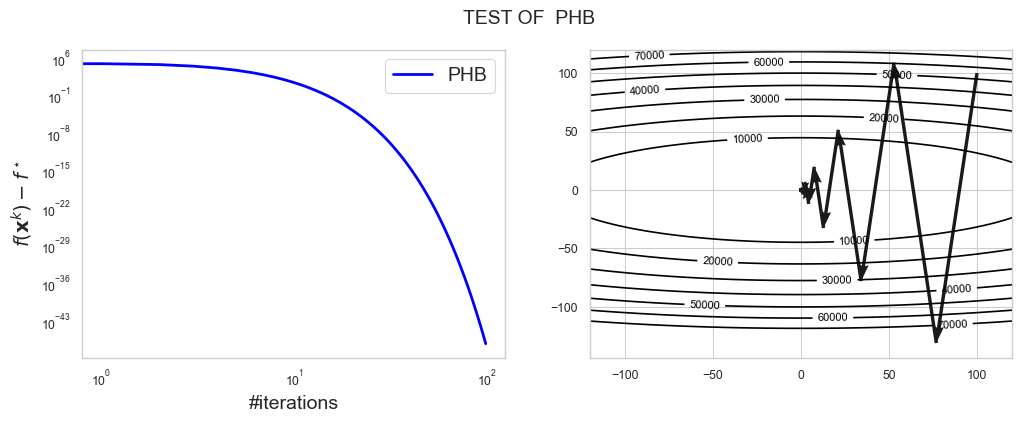

In [47]:
PHB = OptAlgorithm(name="PHB", init_state=PHB_initialize, state_update=PHB_update)

test(PHB)


## NAG-Free Adaptive Acceleration

Here, NAG-Free denotes an adaptive variant of Nesterov’s method that uses line search and local curvature estimates to choose its step size and momentum, without restarts.

Initialize $\mathbf{x}_0=\mathbf{y}_0=$ `x_zero`. Initialize the stored smoothness estimate to `f.lips_grad` and the stored strong-convexity estimate to `f.strng_cvx`; use $1$ and $0$, respectively, if the corresponding value is unavailable or nonpositive. Initialize momentum using the rule below and cache $\nabla f_\mu(\mathbf{y}_0)$.

At iteration $k$, use the following rules:

1. **Line search (`_backtracking_L`).** Starting from half the stored smoothness estimate, double the trial value until
   $$
   f_\mu\!\left(\mathbf{y}_k-\frac{1}{L_k}\nabla f_\mu(\mathbf{y}_k)\right)
   \leq f_\mu(\mathbf{y}_k)-\frac{1}{2L_k}\|\nabla f_\mu(\mathbf{y}_k)\|_2^2.
   $$
   Allow at most 40 doublings; raise `RuntimeError` if the condition still fails. Here $L_k$ denotes the accepted value. Take the gradient step $\mathbf{x}_{k+1}=\mathbf{y}_k-\nabla f_\mu(\mathbf{y}_k)/L_k$.

2. **Local curvature (`_estimate_mu`).** Set $\mathbf{s}_k=\mathbf{x}_{k+1}-\mathbf{x}_k$ and $\mathbf{r}_k=\nabla f_\mu(\mathbf{x}_{k+1})-\nabla f_\mu(\mathbf{x}_k)$. Use
   $$
   \widehat\mu_k=
   \begin{cases}
   \dfrac{\mathbf{s}_k^\top\mathbf{r}_k}{\|\mathbf{s}_k\|_2^2},
      & \|\mathbf{s}_k\|_2^2>0\text{ and }\mathbf{s}_k^\top\mathbf{r}_k>0,\\
   0, & \text{otherwise}.
   \end{cases}
   $$

3. **Momentum (`_momentum_from_L_mu`).** Use
   $$
   a_k=
   \begin{cases}
   \dfrac{\sqrt{L_k}-\sqrt{\widehat\mu_k}}{\sqrt{L_k}+\sqrt{\widehat\mu_k}},
      & L_k>0\text{ and }\widehat\mu_k>0,\\
   0, & \text{otherwise},
   \end{cases}
   \qquad
   \mathbf{y}_{k+1}=\mathbf{x}_{k+1}+a_k(\mathbf{x}_{k+1}-\mathbf{x}_k).
   $$

Store the new iterate, extrapolated point, gradient at that point, and the new estimates $L_k$, $\widehat\mu_k$, and $a_k$ for the next iteration.

Local curvature estimates are not necessarily valid global bounds. This variant should therefore be evaluated experimentally; the accelerated convergence guarantee for AGDstr does not automatically apply to it.

**(a)** (1 point) Complete the cells below to define the state, update rule, initializer, and algorithm object.


In [48]:
@dataclass
class NAGFree_state(OptState):
    x_k: Vector
    y_k: Vector
    g_y: Vector   # cached gradient at y_k
    L_k: float    # stored smoothness estimate
    mu_k: float   # stored strong-convexity estimate
    a_k: float    # momentum

In [49]:
def _backtracking_L(f, y, g, L_prev):
    fy = f(y)
    sq = np.dot(g, g)
    L_try = 0.5 * L_prev
    for _ in range(41):  # the initial trial plus at most 40 doublings
        if f(y - g / L_try) <= fy - 0.5 * sq / L_try:
            return L_try
        L_try *= 2.0
    raise RuntimeError("Line search failed after 40 doublings.")


def _estimate_mu(x_prev, x_cur, g_prev, g_cur):
    s, r = x_cur - x_prev, g_cur - g_prev
    ss, sr = np.dot(s, s), np.dot(s, r)
    return sr / ss if (ss > 0 and sr > 0) else 0.0


def _momentum_from_L_mu(L_k, mu_k):
    if L_k > 0 and mu_k > 0:
        return (np.sqrt(L_k) - np.sqrt(mu_k)) / (np.sqrt(L_k) + np.sqrt(mu_k))
    return 0.0


def NAGFree_update(f, state):
    x_k, y_k, g_y, L_prev, mu_prev, a_k = state
    L_k = _backtracking_L(f, y_k, g_y, L_prev)
    x_next = y_k - g_y / L_k
    mu_k = _estimate_mu(x_k, x_next, f.grad(x_k), f.grad(x_next))
    a_next = _momentum_from_L_mu(L_k, mu_k)
    y_next = x_next + a_next * (x_next - x_k)
    return NAGFree_state(x_k=x_next, y_k=y_next, g_y=f.grad(y_next), L_k=L_k, mu_k=mu_k, a_k=a_next)


def NAGFree_initialize(f, x_zero):
    L = f.lips_grad if (f.lips_grad is not None and f.lips_grad > 0) else 1.0
    mu = f.strng_cvx if (f.strng_cvx is not None and f.strng_cvx > 0) else 0.0
    a = _momentum_from_L_mu(L, mu)
    return NAGFree_state(x_k=x_zero, y_k=x_zero, g_y=f.grad(x_zero), L_k=L, mu_k=mu, a_k=a)

**(b)** (1 point) Test the NAG-Free adaptive acceleration.

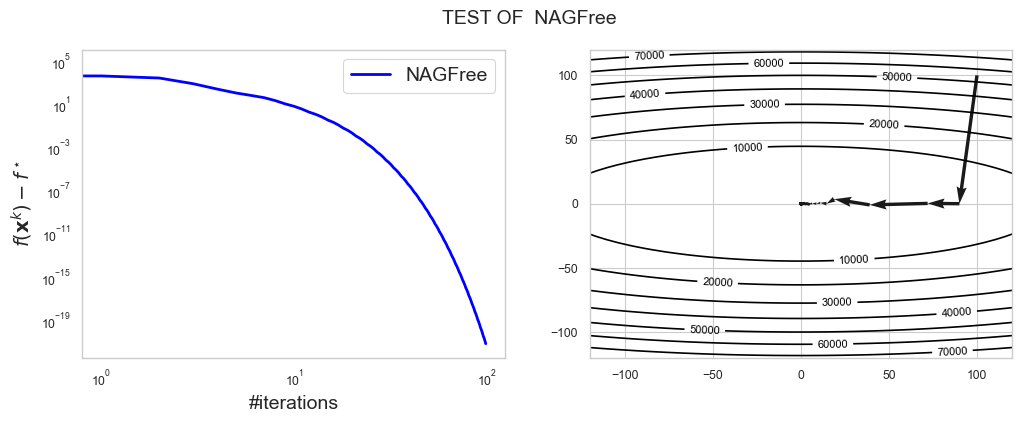

In [50]:
NAGFree = OptAlgorithm(name="NAGFree", init_state=NAGFree_initialize, state_update=NAGFree_update)

test(NAGFree)


## Running the methods - 5 points


We now apply these methods to binary logistic regression, modeling the probability that a basketball shot is successful.

Our data originates from motion tracking data captured by the NBA during the 2015-2016 season.

<img width=50% src='lib/golden_state_shots.png'/>

We consider the `3376` shots made by the Golden State Warriors. The label $b_i$ indicates whether shot $i$ was successful. The five features in $\mathbf{a}_i$ are the shooter’s x- and y-coordinates, distance to the basket, and the minutes and seconds remaining in the quarter.

**(a)** (1 point) Run the following cell to compare the methods you have implemented on the logistic loss:

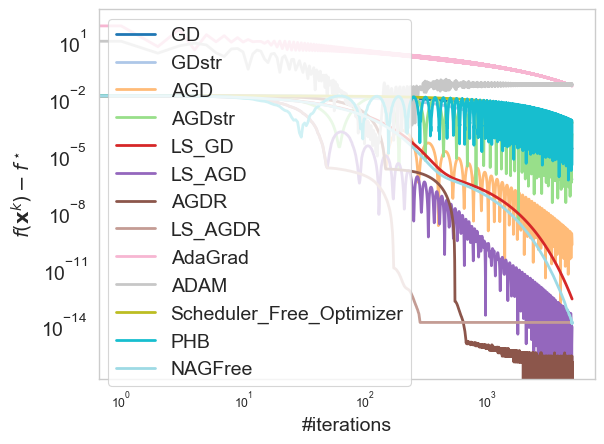

In [51]:
from lib.part_one import f, x_zero, train_accuracy

#Remove methods you have not implemented
methods = [GD, GDstr, AGD, AGDstr, LS_GD, LS_AGD, AGDR, LS_AGDR, AdaGrad, ADAM, SFO, PHB, NAGFree]

plot(methods, f, x_zero, max_iteration=5000, palette="tab20")

**(b)** (2 points) Compare the methods in the plot and discuss whether their observed convergence agrees with the theory.

**(b) Comparison of the methods and relation to the theory.**

*Setting.* The problem is $L$-smooth and $\mu$-strongly convex with $L\approx4.4\cdot10^4$ and $\mu=10^{-3}$, i.e. $\kappa\approx4.4\cdot10^7$. Features are not normalised, so the problem is very ill-conditioned. Gaps $f(\mathbf x^k)-f^\star$ after 5000 iterations (and best value reached) are below. The values below $10^{-15}$ are at the floating-point accuracy of $f^\star$.

| method | gap at $k=5000$ | comment |
|---|---|---|
| GD ($1/L$) | $2\cdot10^{-5}$ | slowest "classical" method |
| GDstr ($2/(L+\mu)$) | $5\cdot10^{-7}$ | about 40$\times$ better than GD |
| AGD | $2\cdot10^{-10}$ (oscillates, best $4\cdot10^{-14}$) | non-monotone |
| AGDstr (theoretical $m$) | $10^{-4}$ (oscillates) | worse than AGD |
| LS_GD | $2\cdot10^{-13}$ | monotone |
| LS_AGD | $8\cdot10^{-15}$ | non-monotone, gap $<10^{-8}$ after 130 iterations |
| AGDR | $\approx10^{-16}$ | monotone, gap $<10^{-10}$ after 543 iterations |
| LS_AGDR | $10^{-14}$ | **fastest**: gap $<10^{-10}$ after 171 iterations |
| NAGFree | $10^{-14}$ | monotone, gap $<10^{-10}$ after 2700 iterations |
| SFO | $5\cdot10^{-4}$ | monotone but slow |
| PHB | $6\cdot10^{-4}$ (oscillates, best $4\cdot10^{-7}$) | oscillates |
| ADAM | $5\cdot10^{-2}$ (best $8\cdot10^{-6}$) | oscillates, does not converge |
| AdaGrad | $4\cdot10^{-2}$ | slowest |

*Agreement with the theory (Lectures 4–5).*

1. **GD vs. AGD.** GD is sublinear $O(1/k)$ in the smooth case, whereas AGD satisfies $f(\mathbf x^k)-f^\star\le\frac{4L}{(k+2)^2}\|\mathbf x^0-\mathbf x^\star\|^2$, which is optimal. AGD is clearly faster than GD, and the bounds hold. At $k=1000$ the observed gaps $3\cdot10^{-3}$ (GD) and $4\cdot10^{-7}$ (AGD) are below the bounds $\approx 0.08$ and $\approx1.5\cdot10^{-4}$, using $\|\mathbf x^0-\mathbf x^\star\|^2\approx10^{-3}$. AGD is **not monotone**: its curve oscillates. The two-orders-of-magnitude gap between theory and practice shows that the bounds are worst-case.
2. **Strong convexity.** The linear-rate bounds for GD, $\big(\frac{\kappa-1}{\kappa+1}\big)^{k/2}$, and for AGD-$\mu L$, $(1-\sqrt{\mu/L})^k$, are essentially vacuous for $\kappa\approx4\cdot10^7$. For instance, $\sqrt{\mu/L}\approx1.5\cdot10^{-4}$ predicts almost no progress in 5000 iterations. Observed progress is much better, since the *local* condition number at $\mathbf x^\star$ is about $1.6\cdot10^3$. The *ordering* predicted by theory (GDstr better than GD, since $2/(L+\mu)$ is the optimal step size) is observed, but the gain is small because $\mu\ll L$ makes $2/(L+\mu)\approx2/L$ only twice the step. The AGD-$\mu L$ momentum computed from the global $\mu,L$ is too large (see (b-2)) and the method underdamps, which is why AGDstr is *worse* than plain AGD.
3. **Line search** (Lecture 5, enhancements). The global $L$ is a worst-case constant. The line search finds local constants $L_k\approx2.8\cdot10^3$ to $5.5\cdot10^3$, about 8 to 16$\times$ smaller than the global $L$. The steps are therefore much larger and LS_GD beats GD by 8 orders of magnitude, at the cost of extra function evaluations per iteration. The same holds for LS_AGD vs AGD.
4. **Restart.** The restart strategy removes the non-monotone behaviour of AGD and gives a much better and clean curve (AGDR). It also yields a linear rate in practice without knowing $\mu$ (Lecture 5: "restart strategies"). It is the best constant-step method. Combining line search and restart (LS_AGDR) is the fastest in number of iterations, as expected. In Lecture 5's ridge-regression experiment, LS-AGD-R was likewise the best curve.
5. **NAGFree.** It adapts both $L_k$ and a local $\widehat\mu_k$ and is monotone without restart. It is much faster than GD and LS_GD, but slower than the restart variants, since the local estimate $\widehat\mu_k$ is not a valid global bound.
6. **Heavy ball (PHB).** The parameters are optimal for *quadratics*, but our problem is not quadratic and $\kappa$ is huge, so $\beta=\big(\frac{\sqrt\kappa-1}{\sqrt\kappa+1}\big)^2\approx0.9996$ is almost $1$. The method oscillates and its guarantee does not transfer, as warned in the notebook.
7. **Adaptive methods.** AdaGrad and ADAM do not need $L$, but they do worse here. AdaGrad's first step has norm $\alpha=1$, very large compared with $\|\mathbf x^\star\|\approx0.03$, which causes an overshoot (gap $\approx8$ at $k=10$). Its step size $\alpha/\sqrt{Q_k}$ then decays slowly and it uses a single scalar for all directions. ADAM is fast at the start ($9\cdot10^{-4}$ at $k=100$), but its constant $\alpha=0.1$ yields coordinate steps of size $\approx0.1$ regardless of the gradient size, so it oscillates around $\mathbf x^\star$ and does not converge, which agrees with the remark that ADAM may fail on convex problems. SFO is stable but only sublinear (see above).

*Conclusion.* The ranking agrees with theory (acceleration > GD; restart/line search > constant step; $\mu$-dependent parameters help only when the constants are accurate). The absolute rates are far better than the worst-case bounds suggest because of local curvature.

Pick the best performing method and run the following cell to display the training accuracy of your solution:

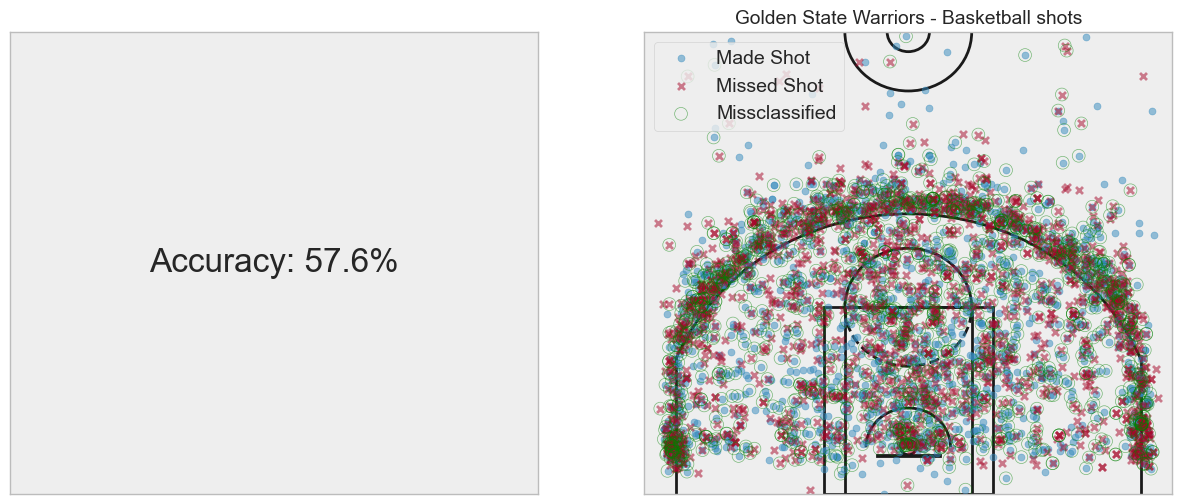

In [52]:
method = LS_AGDR  # FILL: choose a method (fastest: gap < 1e-10 after ~170 iterations)
run_trace = run(method, f, x_zero, 5000)
last_x_k = run_trace.sequence[-1]

train_accuracy(run_trace.sequence[-1])

**(c)** (2 points) Given we have access to as many as `84467` distinct shots from all teams that played in the 2015–2016 season, how could we use them to improve our model? What effect would this have on the computational cost of our deterministic methods?

**(c) Using the 84467 shots of all teams.**

*How to use them.* We can minimise the same regularised logistic loss with $n=84467$ samples ($\approx25\times$ more) instead of $3376$, which is the empirical-risk-minimisation setting of Lecture 1. Equivalently, we can use all of the data as the training set. More samples reduce the variance of the estimator and the risk of overfitting, so the learned $\mathbf x^\star$ generalises better to new shots (the sampling error of the empirical risk decreases with $n$). It also lets us hold out a validation set to choose $\mu$. The model class is still very limited, since $5$ features give a nearly linear classifier, so the accuracy gain is bounded. Concretely, with our `LS_AGDR` the Warriors-only model (trained on $3376$ shots) has $57.6\%$ training accuracy and $58.4\%$ on all shots. Training on all shots gives $59.9\%$ on all shots and $58.8\%$ on the Warriors' shots, which is better on both. In both cases the Warriors-only model is not much better than the majority-class baseline ($51\%$ and $55\%$), which shows how limited the 5-feature linear model is. More data therefore helps, but richer features would help more. Note also that the data are drawn from different teams/players, so there is a distribution shift with respect to the Warriors alone, which should be considered.

*Effect on computational cost.* A deterministic method needs, at every iteration, the *full* gradient $\nabla f_\mu(\mathbf x)=\frac1n\sum_{i=1}^n\nabla f_i(\mathbf x)$, which costs $O(np)$. Hence the per-iteration cost grows **linearly in $n$**: $\approx25\times$ more (we measured a gradient evaluation to be $\approx29\times$ slower on the full data). The number of iterations does not decrease with $n$: the rates above depend on $L$ and $\mu$, and since $f$ is an *average*, $L=\frac1n\|A\|_F^2+\mu$ is essentially unchanged ($4.4\cdot10^4$ vs $4.2\cdot10^4$). The total cost to reach a given accuracy $\epsilon$ is therefore $O(n\,p\,\cdot\#\text{iterations}(\epsilon))$, which scales linearly with the data size. This is the motivation for the next notebook: stochastic methods use $\nabla f_i$ of a single sample (or a mini-batch), so the cost of one iteration is independent of $n$ ($O(p)$), at the price of noisier iterates and slower per-iteration convergence.

In the next notebook, you will use stochastic methods to reduce the computational cost of a single iteration.